# EcoData · S8 — Procesamiento en streaming con Spark
**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

Ventanas de tiempo, watermarking, checkpointing, deduplicación e intervalo de disparo, aplicados a las lecturas de **PM2.5 / PM10 de Juliaca** (Open-Meteo / CAMS) que EcoData ya mueve por Kafka.

| Guía S8 | EcoData |
|---|---|
| topic `atmos-eventos` (ESP32) | **`ecodata-s08-aire`** (topic propio: las pruebas de tardíos y duplicados **no ensucian** `atmos-aire` ni los contadores de Grafana de S12) |
| sensores `esp32-*`, temperatura | lecturas de calidad del aire: **`pm25`**, `pm10` |
| ventana 10 s, watermark 10 s | ventana **6 h**, watermark **2 h** (los mismos márgenes del job de producción de S12; ver justificación abajo) |
| productor corriendo en vivo | horas reales de la API **reenviadas a ritmo controlado** (1 cada 1,5–2 s) |

> **Transparencia:** el dato de EcoData es horario y modelado (CAMS, ≈45 km), no un sensor físico. Para poder *ver* ventanas que se cierran en minutos y no en horas, el cuaderno reenvía horas reales en orden cronológico: el **tiempo de evento** es el de la hora medida (cada evento avanza 1 hora), el **tiempo de procesamiento** es el reloj de tu computadora. Esa diferencia es justamente lo que la sesión enseña.
>
> **Antes de empezar:** Kafka levantado y los demás cuadernos de Spark cerrados (Kernel → Shut down). Los experimentos se ejecutan **de a uno, en orden**. No relances los jobs de S12 mientras tanto.

**Elección de márgenes (4.1, punto 2):** ventana de **6 h** porque resume un tramo del día con sentido sanitario (mañana, tarde, noche) y coincide con el job de producción; watermark de **2 h** porque el dato llega por hora: tolera *una* lectura tardía y obliga a cerrar la ventana poco después. Lo que se gana: estado acotado y resultados definitivos pronto. Lo que se pierde: una lectura que llegue con más de 2 h de retraso se descarta en silencio (se comprueba en la sección 6).

## 0. Preparación

In [2]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

import shutil, glob
TOPIC = "ecodata-s08-aire"
crear_topic(TOPIC)

def chk(nombre):
    """Carpeta de checkpoint limpia para un experimento nuevo."""
    ruta = f"./artifacts/s08/chk_{nombre}"; shutil.rmtree(ruta, ignore_errors=True); return ruta

def detener_todo():
    for q in spark.streams.active:
        try: q.stop()
        except Exception: pass

# Pool de horas reales, en orden cronológico (la API reciente trae pocas horas; se completa con el histórico real)
try:
    serie = pub_aire.desde_api()
except Exception as ex:
    print("API no disponible:", type(ex).__name__); serie = []
if len(serie) < 96:
    print(f"La API trajo {len(serie)} horas; uso el histórico real de Juliaca (origen openmeteo-replay)")
    serie = desde_archivo()
serie = sorted(serie)[-96:]
assert len(serie) >= 96, "necesito al menos 96 horas"
def ev(i, origen="openmeteo-replay"):
    t, a, b = serie[i % len(serie)]
    return aire.evento(t, a, b, origen)
print("horas disponibles:", len(serie), "·", datetime.fromtimestamp(serie[0][0]/1000, timezone.utc), "→", datetime.fromtimestamp(serie[-1][0]/1000, timezone.utc))
print("ejemplo de evento:", json.dumps(ev(0)))

el topic ya existía: ecodata-s08-aire
La API trajo 51 horas; uso el histórico real de Juliaca (origen openmeteo-replay)
horas disponibles: 96 · 2023-12-28 00:00:00+00:00 → 2023-12-31 23:00:00+00:00
ejemplo de evento: {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 6.2, "pm10": 8.9, "origen": "openmeteo-replay", "timestamp": 1703721600000}


## 1. SparkSession con el conector de Kafka (3.1–3.2)
En EcoData el contenedor de Jupyter ya está en la red de Kafka (`kafka:9092`), así que **no hace falta** el `compose.kafka.yml` de la guía. El puerto 4053 de la Spark UI evita chocar con S9 (4050), S10 (4051), S11 (4052) y los jobs de S12 (4040).

In [3]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s08").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4053")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

lote = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
        .option("subscribe", TOPIC).option("startingOffsets", "earliest").load())
print("lectura BATCH, mensajes hoy en el topic:", lote.count(), "(0 es normal la primera vez)")

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-304e32bb-2616-4451-8266-114d0a925ffe;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0
lectura BATCH, mensajes hoy en el topic: 0 (0 es normal la primera vez)


## 2. Lectura streaming con esquema explícito (3.3–3.4)
`readStream` crea un *plan*, no una tabla: `crudo.show()` fallaría. El esquema es explícito porque un stream no tiene fin para inferirlo. `ts` es el **tiempo de evento** (la hora medida), distinto de `kafkaTimestamp` (cuándo llegó al broker).

In [4]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", TOPIC).option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
print("es un stream:", crudo.isStreaming)
eventos = (crudo.select(F.col("timestamp").alias("kafkaTimestamp"), F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("kafkaTimestamp", "e.*")
           .withColumn("ts", (F.col("timestamp") / 1000).cast("timestamp")))
eventos.printSchema()
try:
    crudo.count()
except Exception as ex:
    print("\nSi se intenta materializar un stream:", type(ex).__name__, "→", str(ex).splitlines()[0][:110])

es un stream: True
root
 |-- kafkaTimestamp: timestamp (nullable = true)
 |-- tipoEvento: string (nullable = true)
 |-- sensorId: string (nullable = true)
 |-- pm25: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- ts: timestamp (nullable = true)


Si se intenta materializar un stream: AnalysisException → Queries with streaming sources must be executed with writeStream.start(), or from a streaming table or flow de


## 3. Utilidades comunes
Jupyter no muestra la consola de Spark, así que cada consulta usa `foreachBatch` y **recolecta sus filas en una lista de Python** (equivale al sink `console` de la guía, pero queda visible y reutilizable como evidencia).

In [5]:
def recolector(df, modo, nombre, trigger="4 seconds"):
    """Arranca una consulta que guarda cada fila de salida en una lista, con el batchId que la produjo."""
    salida = []
    def fb(batch, bid):
        for r in batch.collect():
            d = r.asDict(); d["batchId"] = bid; salida.append(d)
    q = (df.writeStream.outputMode(modo).foreachBatch(fb)
         .option("checkpointLocation", chk(nombre)).queryName(nombre)
         .trigger(processingTime=trigger).start())
    return q, salida

def agregar(df, wm=None, ancho="6 hours", paso=None):
    d = df.withWatermark("ts", wm) if wm else df
    w = F.window("ts", ancho, paso) if paso else F.window("ts", ancho)
    return (d.groupBy(w, "sensorId")
             .agg(F.count("*").alias("n"), F.round(F.avg("pm25"), 2).alias("pm25_prom"), F.max("pm25").alias("pm25_max"))
             .select(F.col("window.start").alias("ventana_inicio"), F.col("window.end").alias("ventana_fin"),
                     "sensorId", "n", "pm25_prom", "pm25_max"))

def estado(q):
    """Filas de estado que la consulta mantiene en memoria, micro-lote a micro-lote."""
    f = []
    for p in q.recentProgress:
        if p["numInputRows"] > 0:
            so = p["stateOperators"][0]["numRowsTotal"] if p["stateOperators"] else None
            f.append({"batchId": p["batchId"], "filas_entrada": p["numInputRows"], "ventanas_en_estado": so,
                      "watermark": p.get("eventTime", {}).get("watermark")})
    return pd.DataFrame(f)
print("utilidades listas")

utilidades listas


## 4. Ventana fija 6 h: SIN watermark frente a CON watermark (3.7–3.8)
Dos consultas **sobre el mismo flujo**: una sin watermark (`complete`: reimprime todo, guarda todas las ventanas jamás vistas) y otra con `withWatermark("ts","2 hours")` (`update`: solo lo que cambió; las ventanas cerradas se olvidan). Se reenvían 60 horas reales (≈ 10 ventanas de 6 h) a 1,5 s por hora.

In [6]:
detener_todo()
q_sin, sal_sin = recolector(agregar(eventos), "complete", "e1_sin_watermark")
q_con, sal_con = recolector(agregar(eventos, wm="2 hours"), "update", "e1_con_watermark")
time.sleep(8)                                    # deja que las consultas arranquen antes de publicar
hilo = publicar_paced(TOPIC, [ev(i) for i in range(60)], pausa_s=1.5)
print("publicando 60 horas reales (~90 s). Espera a que termine la celda siguiente.")

publicando 60 horas reales (~90 s). Espera a que termine la celda siguiente.


In [7]:
hilo.join(timeout=200); time.sleep(14)         # fin de la publicación + último micro-lote
print("=== SIN watermark: ventanas en estado por micro-lote (crece sin límite) ===")
e_sin = estado(q_sin); print(e_sin.to_string(index=False))
print("\n=== CON watermark (2 h): ventanas en estado por micro-lote (acotado) ===")
e_con = estado(q_con); print(e_con.to_string(index=False))

=== SIN watermark: ventanas en estado por micro-lote (crece sin límite) ===
 batchId  filas_entrada  ventanas_en_estado watermark
       1              1                   1      None
       2              3                   1      None
       3              2                   1      None
       4              3                   2      None
       5              3                   2      None
       6              2                   3      None
       7              3                   3      None
       8              3                   4      None
       9              2                   4      None
      10              3                   5      None
      11              3                   5      None
      12              2                   5      None
      13              3                   6      None
      14              3                   6      None
      15              2                   7      None
      16              3                   7      None
      

In [8]:
# Lo que cada modo entrega en un micro-lote concreto
ultimo = max(r["batchId"] for r in sal_sin)
print(f"SIN watermark · micro-lote {ultimo}: reimprime TODAS las ventanas ({sum(1 for r in sal_sin if r['batchId']==ultimo)} filas)")
print(f"CON watermark · total de filas emitidas en toda la corrida (solo ventanas que cambiaron): {len(sal_con)}")
pd.DataFrame([r for r in sal_con if r["batchId"] == max(r2["batchId"] for r2 in sal_con)]).drop(columns="batchId")

SIN watermark · micro-lote 24: reimprime TODAS las ventanas (10 filas)
CON watermark · total de filas emitidas en toda la corrida (solo ventanas que cambiaron): 28


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max
0,2023-12-30 06:00:00,2023-12-30 12:00:00,openmeteo-cams-juliaca,6,8.68,10.5


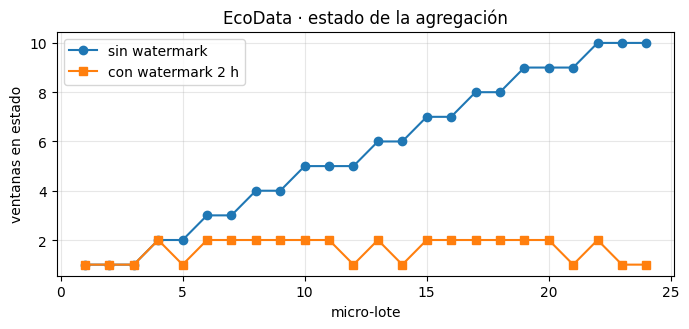

In [9]:
# Evidencia gráfica: estado en memoria, sin y con watermark
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(e_sin["batchId"], e_sin["ventanas_en_estado"], "o-", label="sin watermark")
ax.plot(e_con["batchId"], e_con["ventanas_en_estado"], "s-", label="con watermark 2 h")
ax.set_xlabel("micro-lote"); ax.set_ylabel("ventanas en estado"); ax.set_title("EcoData · estado de la agregación"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Captura:** las dos tablas de estado (la columna `ventanas_en_estado` sube sin tope en la primera y se estabiliza en la segunda) y el gráfico. En tu informe, explica cada modo de salida y por qué `complete` solo es posible sin watermark.

In [10]:
detener_todo(); print("consultas detenidas")

consultas detenidas


## 5. Ventana deslizante 6 h con paso de 2 h (3.9)
Con el paso menor que el ancho, **cada lectura cae en tres ventanas** (`6 h / 2 h = 3`). Sirve para suavizar la métrica, a costa de guardar más estado.

In [11]:
detener_todo()
q_des, sal_des = recolector(agregar(eventos, wm="2 hours", ancho="6 hours", paso="2 hours"), "update", "e2_deslizante")
time.sleep(8)
hilo = publicar_paced(TOPIC, [ev(i) for i in range(24)], pausa_s=1.5)
hilo.join(timeout=120); time.sleep(12)
q_des.stop()
df_des = pd.DataFrame(sal_des).drop(columns="batchId").drop_duplicates(["ventana_inicio", "sensorId"], keep="last").sort_values("ventana_inicio")
print("ventanas distintas que produjeron las 24 horas publicadas:", len(df_des), "(con ventana fija serían ~4–5)")
df_des

ventanas distintas que produjeron las 24 horas publicadas: 14 (con ventana fija serían ~4–5)


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max
6,2023-12-27 20:00:00,2023-12-28 02:00:00,openmeteo-cams-juliaca,2,6.20,6.2
8,2023-12-27 22:00:00,2023-12-28 04:00:00,openmeteo-cams-juliaca,4,6.00,6.2
9,2023-12-28 00:00:00,2023-12-28 06:00:00,openmeteo-cams-juliaca,6,6.23,6.7
11,2023-12-28 02:00:00,2023-12-28 08:00:00,openmeteo-cams-juliaca,6,6.23,6.7
18,2023-12-28 04:00:00,2023-12-28 10:00:00,openmeteo-cams-juliaca,6,6.20,6.7
21,2023-12-28 06:00:00,2023-12-28 12:00:00,openmeteo-cams-juliaca,6,5.82,6.3
20,2023-12-28 08:00:00,2023-12-28 14:00:00,openmeteo-cams-juliaca,6,4.42,5.8
23,2023-12-28 10:00:00,2023-12-28 16:00:00,openmeteo-cams-juliaca,6,3.02,5.6
29,2023-12-28 12:00:00,2023-12-28 18:00:00,openmeteo-cams-juliaca,6,1.57,2.1
32,2023-12-28 14:00:00,2023-12-28 20:00:00,openmeteo-cams-juliaca,6,1.22,1.6


**Captura:** la tabla. Elige una hora concreta y señala las tres ventanas solapadas que la contienen.

## 6. Dato tardío y watermark (3.11 · punto 3 de la actividad)
Se publican 25 horas en orden y luego, en el medio del flujo:
- `ec-tolerado`: una lectura **1 h** más vieja que la última (dentro del margen de 2 h → **debe aparecer**).
- `ec-tardio`: una lectura **24 h** más vieja (fuera del margen → **debe desaparecer sin ningún error**).

Una segunda consulta, **sin agregación**, lee el mismo flujo en crudo: prueba que `ec-tardio` *sí llegó* a Spark y que, aun así, la agregación no lo cuenta. (Advertencia de arranque en frío: si el tardío fuera el primer mensaje que ve la consulta, el watermark aún no tendría referencia y se aceptaría; por eso primero van 25 horas normales.)

In [12]:
detener_todo()
q_raw, sal_raw = recolector(eventos.select("sensorId", "ts", "pm25", "origen"), "append", "e3_crudo")
q_agg, sal_agg = recolector(agregar(eventos, wm="2 hours"), "update", "e3_agregado")
time.sleep(8)

normales = [ev(i) for i in range(31)]
ultimo_ts = normales[24]["timestamp"]
tolerado = ev(20, "prueba-tolerado"); tolerado.update(sensorId="ec-tolerado", timestamp=ultimo_ts - 1*3600*1000)
tardio   = ev(5,  "prueba-tardio");   tardio.update(sensorId="ec-tardio",   timestamp=ultimo_ts - 24*3600*1000)
flujo = normales[:25] + [tolerado, tardio] + normales[25:]
hilo = publicar_paced(TOPIC, flujo, pausa_s=1.5)
print("publicando", len(flujo), "eventos (~50 s). Tardío =", datetime.fromtimestamp(tardio["timestamp"]/1000, timezone.utc), "UTC")

publicando 33 eventos (~50 s). Tardío = 2023-12-28 00:00:00+00:00 UTC


In [13]:
hilo.join(timeout=120); time.sleep(14)
crudo_df = pd.DataFrame(sal_raw)
agg_df = pd.DataFrame(sal_agg)
for s in ("ec-tolerado", "ec-tardio"):
    print(f"{s:12s} · llegó a Spark (lectura cruda): {(crudo_df.sensorId == s).sum()} vez/veces · "
          f"aparece en la agregación con watermark: {'SÍ' if (agg_df.sensorId == s).any() else 'NO'}")
print("\nEl tardío en crudo:")
display(crudo_df[crudo_df.sensorId == "ec-tardio"][["batchId", "sensorId", "ts", "pm25", "origen"]])
print("Filas de ventana con sensorId distinto del principal (el tolerado debe estar, el tardío no):")
display(agg_df[agg_df.sensorId.str.startswith("ec-t")].drop_duplicates(["ventana_inicio", "sensorId"], keep="last"))

ec-tolerado  · llegó a Spark (lectura cruda): 1 vez/veces · aparece en la agregación con watermark: SÍ
ec-tardio    · llegó a Spark (lectura cruda): 1 vez/veces · aparece en la agregación con watermark: NO

El tardío en crudo:


,batchId,sensorId,ts,pm25,origen
26,11,ec-tardio,2023-12-28,6.7,prueba-tardio


Filas de ventana con sensorId distinto del principal (el tolerado debe estar, el tardío no):


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max,batchId
11,2023-12-28 18:00:00,2023-12-29,ec-tolerado,1,0.9,0.9,10


In [14]:
detener_todo(); print("consultas detenidas")

consultas detenidas


**Captura:** el `print` de dos líneas y las dos tablas. El mensaje clave: `ec-tardio` aparece en crudo y **no** en la agregación; `ec-tolerado` aparece en ambas.

## 7. Deduplicación acotada por watermark (3.12 · punto 4)
Se publica **dos veces** la misma lectura (`ec-duplicado`). La consulta de crudo la ve dos veces; la deduplicada, una.

> Detalle técnico: `dropDuplicates` solo puede limpiar su estado si la **columna de tiempo del watermark (`ts`) forma parte de las columnas de deduplicación**; por eso aquí se usa `["sensorId", "ts"]` y no el `timestamp` numérico. Con el numérico, Spark guardaría cada identificador para siempre.

In [15]:
detener_todo()
q_raw2, sal_raw2 = recolector(eventos.select("sensorId", "ts", "pm25", "origen"), "append", "e4_crudo")
dedup = eventos.withWatermark("ts", "2 hours").dropDuplicates(["sensorId", "ts"]).select("sensorId", "ts", "pm25", "origen")
q_ded, sal_ded = recolector(dedup, "append", "e4_dedup", trigger="3 seconds")
time.sleep(8)

base = [ev(i) for i in range(10)]
dup = ev(9, "prueba-duplicado"); dup["sensorId"] = "ec-duplicado"
hilo = publicar_paced(TOPIC, base + [dup, dup] + [ev(i) for i in range(10, 16)], pausa_s=1.0)
hilo.join(timeout=60); time.sleep(12)

r = pd.DataFrame(sal_raw2); d = pd.DataFrame(sal_ded)
print("ec-duplicado publicado 2 veces → lectura cruda:", (r.sensorId == "ec-duplicado").sum(),
      "· tras dropDuplicates con watermark:", (d.sensorId == "ec-duplicado").sum())
display(d[d.sensorId == "ec-duplicado"])
print("total crudo:", len(r), "· total deduplicado:", len(d))

ec-duplicado publicado 2 veces → lectura cruda: 2 · tras dropDuplicates con watermark: 1


,sensorId,ts,pm25,origen,batchId
9,ec-duplicado,2023-12-28 09:00:00,5.6,prueba-duplicado,4


total crudo: 18 · total deduplicado: 17


In [16]:
detener_todo(); print("consultas detenidas")

consultas detenidas


**Captura:** el `print` (2 → 1) y la tabla. Relaciónalo con la semántica *at-least-once* de Kafka (S6): el duplicado es lo que un reintento podría producir.

## 8. Intervalo de disparo: 1 s frente a 6 s (3.13 · punto 5)
Mismo flujo, mismo tiempo de reloj (15 s cada uno). Además del `batchId` que pide la guía se mide cuántas filas procesó cada micro-lote y la **latencia real** (llegada a Kafka → procesamiento), que es lo que el intervalo compromete.

In [17]:
detener_todo()
def medir(intervalo, segundos):
    nombre = "trg_" + intervalo.replace(" ", "_")
    df = eventos.withColumn("lat_ms", F.unix_millis(F.current_timestamp()) - F.unix_millis(F.col("kafkaTimestamp")))
    q = (df.writeStream.outputMode("append").format("memory").queryName(nombre)
         .trigger(processingTime=intervalo).start())
    q.awaitTermination(segundos); q.stop()
    prog = [p for p in q.recentProgress]
    lat = spark.sql(f"SELECT avg(lat_ms) a, max(lat_ms) m FROM {nombre}").first()
    return {"intervalo": intervalo, "ultimo_batchId": max((p["batchId"] for p in prog), default=None),
            "microlotes_con_datos": sum(1 for p in prog if p["numInputRows"] > 0),
            "filas_procesadas": sum(p["numInputRows"] for p in prog),
            "latencia_prom_ms": round(lat["a"] or 0), "latencia_max_ms": lat["m"]}

hilo = publicar_paced(TOPIC, [ev(i) for i in range(120)], pausa_s=0.4)   # flujo continuo ~48 s
time.sleep(3)
res = [medir("1 second", 15), medir("6 seconds", 15)]
hilo.join(timeout=60)
pd.DataFrame(res)

26/11/06 02:20:30 ERROR WriteToDataSourceV2Exec: Data source write support MicroBatchWrite[epoch: 15, writer: org.apache.spark.sql.execution.streaming.sources.MemoryStreamingWrite@1540ce84] is aborting.
26/11/06 02:20:30 ERROR WriteToDataSourceV2Exec: Data source write support MicroBatchWrite[epoch: 15, writer: org.apache.spark.sql.execution.streaming.sources.MemoryStreamingWrite@1540ce84] aborted.
26/11/06 02:20:30 ERROR Utils: Aborting task
org.apache.spark.TaskKilledException: Stage cancelled: [SPARK_JOB_CANCELLED] Job 123 cancelled Query trg_1_second [id = 0e957bed-d3cd-4586-bd7e-c696f040362a, runId = 3dae19f2-b160-4d8d-8dfe-9db331f6205a] was stopped SQLSTATE: XXKDA
	at org.apache.spark.TaskContextImpl.killTaskIfInterrupted(TaskContextImpl.scala:342)
	at org.apache.spark.InterruptibleIterator.hasNext(InterruptibleIterator.scala:36)
	at scala.collection.Iterator$$anon$10.hasNext(Iterator.scala:610)
	at scala.collection.Iterator$$anon$9.hasNext(Iterator.scala:593)
	at scala.collectio

,intervalo,ultimo_batchId,microlotes_con_datos,filas_procesadas,latencia_prom_ms,latencia_max_ms
0,1 second,14,14,34,522,1010
1,6 seconds,2,2,29,2771,5667


**Captura:** la tabla. Lectura esperada: con 1 s hay más micro-lotes y menos filas por lote, y la latencia es menor; con 6 s ocurre lo contrario. El log puede mostrar `TaskKilledException` al detener: es ruido de `stop()`, no una falla.

**Para EcoData:** los datos llegan por hora, así que un disparo de 1 s es puro gasto; el job de producción dispara cada 5 min. Para una alerta de episodio (que debe salir en minutos) ese intervalo ya es más que suficiente.

## 9. Checkpoint: qué guarda y qué pasa al reiniciar (3.10)
Se inspecciona el checkpoint de la consulta con watermark de la sección 4 (la que tiene estado).

In [18]:
base_chk = "./artifacts/s08/chk_e1_con_watermark"
print("Contenido del checkpoint:", sorted(os.listdir(base_chk)))
for sub in ("offsets", "commits", "state"):
    ruta = os.path.join(base_chk, sub)
    if os.path.isdir(ruta):
        n = sum(len(f) for _, _, f in os.walk(ruta))
        print(f"  {sub}/ → {n} archivos")
ult = sorted(os.listdir(base_chk + "/offsets"), key=lambda x: int(x) if x.isdigit() else -1)[-1]
print(f"\nÚltimo archivo de offsets (lote {ult}):")
print(open(f"{base_chk}/offsets/{ult}").read())

Contenido del checkpoint: ['.metadata.crc', 'commits', 'metadata', 'offsets', 'sources', 'state']
  offsets/ → 52 archivos
  commits/ → 52 archivos
  state/ → 170 archivos

Último archivo de offsets (lote 25):
v1
{"batchWatermarkMs":1703926800000,"batchTimestampMs":1793930796005,"conf":{"spark.sql.streaming.stateStore.providerClass":"org.apache.spark.sql.execution.streaming.state.HDFSBackedStateStoreProvider","spark.sql.streaming.stateStore.rocksdb.mergeOperatorVersion":"2","spark.sql.streaming.stateStore.rocksdb.formatVersion":"5","spark.sql.streaming.queryEvolution.enableSourceEvolution":"false","spark.sql.streaming.stateStore.encodingFormat":"unsaferow","spark.sql.streaming.statefulOperator.useStrictDistribution":"true","spark.sql.streaming.flatMapGroupsWithState.stateFormatVersion":"2","spark.sql.streaming.multipleWatermarkPolicy":"min","spark.sql.streaming.stateStore.rowChecksum.enabled":"false","spark.sql.streaming.aggregation.stateFormatVersion":"2","spark.sql.function.protobufE

- `offsets/`: hasta qué offset de cada partición se leyó, por micro-lote.
- `commits/`: qué micro-lotes terminaron de escribirse.
- `state/`: el contenido de las ventanas abiertas.

El reinicio con el mismo checkpoint se **demuestra en la sección 11** (segunda corrida a Parquet): la consulta retoma desde el último offset confirmado, sin releer el topic y sin duplicar.

## 10. Errores provocados a propósito (para el apartado «Error o hallazgo»)

In [19]:
detener_todo()
def intentar(titulo, fn):
    try:
        fn(); print(f"· {titulo}: NO falló en esta versión de Spark")
    except Exception as ex:
        print(f"· {titulo}:\n    {type(ex).__name__}: {str(ex).splitlines()[0][:230]}")

def sin_checkpoint():
    q = agregar(eventos, wm="2 hours").writeStream.outputMode("update").foreachBatch(lambda b, i: None).start()
    q.stop()
def update_a_parquet():
    q = (agregar(eventos, wm="2 hours").writeStream.outputMode("update").format("parquet")
         .option("path", "./artifacts/s08/no_usar").option("checkpointLocation", chk("e5_error")).start())
    q.stop()
intentar("Consulta con estado SIN checkpointLocation", sin_checkpoint)
intentar("Agregación en modo update escrita directo a Parquet", update_a_parquet)
detener_todo()

· Consulta con estado SIN checkpointLocation: NO falló en esta versión de Spark
· Agregación en modo update escrita directo a Parquet:
    AnalysisException: [STREAMING_OUTPUT_MODE.UNSUPPORTED_DATASOURCE] Invalid streaming output mode: update. This output mode is not supported in Data Source parquet. SQLSTATE: 42KDE


**Captura:** los dos mensajes. Cualquiera de ellos puede ser tu «error diagnosticado» del informe (preguntas de defensa 2 y 4).

## 11. Persistencia en Parquet con checkpoint: dos corridas que acumulan (3.6 · punto 6)
Primera corrida: 20 horas. Se detiene la consulta. Segunda corrida: **mismo checkpoint, misma carpeta**, 15 horas nuevas. Debe acumular (35 filas), no sobreescribir, y retomar donde quedó.

In [20]:
RUTA = "./artifacts/s08/parquet_aire"; CHK_P = chk("e6_parquet"); shutil.rmtree(RUTA, ignore_errors=True)
def corrida(horas, etiqueta):
    q = (eventos.select("sensorId", "pm25", "pm10", "ts", "origen").writeStream.outputMode("append").format("parquet")
         .option("path", RUTA).option("checkpointLocation", CHK_P).trigger(processingTime="4 seconds").start())
    time.sleep(6)
    publicar_paced(TOPIC, [ev(i) for i in horas], pausa_s=1.0).join(timeout=60)
    time.sleep(12); q.stop()
    lotes = [p["batchId"] for p in q.recentProgress if p["numInputRows"] > 0]
    n = spark.read.parquet(RUTA).count()
    print(f"{etiqueta}: micro-lotes {lotes} · filas totales en Parquet: {n}")
    return n, lotes

n1, l1 = corrida(range(0, 20), "Corrida 1")
n2, l2 = corrida(range(20, 35), "Corrida 2")
print("\n¿Acumuló en vez de sobreescribir?", n2 > n1, f"({n1} → {n2}; esperado +15 = {n1 + 15})")
print("¿La corrida 2 retomó desde el checkpoint (batchId mayor que el último de la corrida 1)?", bool(l1 and l2 and min(l2) > max(l1)))

Corrida 1: micro-lotes [1, 2, 3, 4, 5, 6] · filas totales en Parquet: 20


Corrida 2: micro-lotes [7, 8, 9, 10, 11] · filas totales en Parquet: 35

¿Acumuló en vez de sobreescribir? True (20 → 35; esperado +15 = 35)
¿La corrida 2 retomó desde el checkpoint (batchId mayor que el último de la corrida 1)? True


In [21]:
spark.read.parquet(RUTA).groupBy("sensorId").agg(F.count("*").alias("filas"), F.min("ts").alias("desde"), F.max("ts").alias("hasta")).show(truncate=False)
print("Archivos Parquet en disco:", len(glob.glob(RUTA + "/*.parquet")))
print("Offsets confirmados en el checkpoint:", sorted(os.listdir(CHK_P + "/offsets"))[-3:])

+----------------------+-----+-------------------+-------------------+
|sensorId              |filas|desde              |hasta              |
+----------------------+-----+-------------------+-------------------+
|openmeteo-cams-juliaca|35   |2023-12-28 00:00:00|2023-12-29 10:00:00|
+----------------------+-----+-------------------+-------------------+

Archivos Parquet en disco: 12
Offsets confirmados en el checkpoint: ['7', '8', '9']


**Captura:** la salida de las dos corridas con el veredicto, y la tabla resumen.

## 12. Cierre
Detén lo que quede activo y guarda estas capturas (cada una **con el reloj del sistema y tu usuario/perfil visibles**):

1. Sección 2 — `printSchema` y la excepción al materializar un stream.
2. Sección 4 — tablas de estado sin/con watermark + gráfico.
3. Sección 5 — ventana deslizante.
4. Sección 6 — tardío descartado y tolerado aceptado.
5. Sección 7 — duplicado (2 → 1).
6. Sección 8 — comparación de intervalos de disparo.
7. Sección 9 — contenido del checkpoint.
8. Sección 10 — errores provocados.
9. Sección 11 — dos corridas que acumulan.
10. Kafka UI (http://localhost:48085) con el topic `ecodata-s08-aire`.

In [ ]:
detener_todo()
spark.stop()
print("listo. Sube este cuaderno y la carpeta artifacts/s08 (sin los checkpoints) a tu repositorio el mismo día.")